<a href="https://colab.research.google.com/github/Oyakata32/Lesson-23/blob/main/Lekcja_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#zadanie 1
# kNN -- klasyfikacja kwiatów irysów
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
# Wczytanie danych
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
print("Kształt danych:", X.shape)
print("Klasy:", iris.target_names)
print()
# Podział na train/test
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y
)
# Standaryzacja -- WAŻNA dla kNN (algorytm oparty na odległościach)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Trening kNN z k=3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
# Predykcja i ewaluacja
y_pred = knn.predict(X_test_scaled)
print("Raport klasyfikacji:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Kształt danych: (150, 4)
Klasy: ['setosa' 'versicolor' 'virginica']

Raport klasyfikacji:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



Kształt danych: (150, 4)
Klasy: ['setosa' 'versicolor' 'virginica']



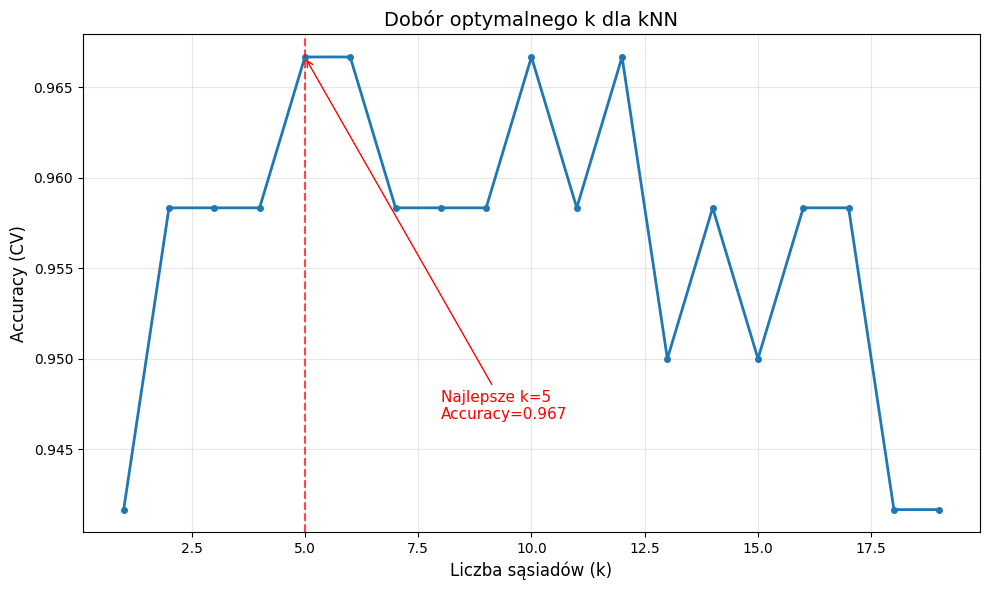

Optymalne k: 5, Accuracy: 0.9667


In [6]:
#zadanie 2
# kNN -- klasyfikacja kwiatów irysów
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
# Wczytanie danych
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
print("Kształt danych:", X.shape)
print("Klasy:", iris.target_names)
print()
# Podział na train/test
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y
)
# Standaryzacja -- WAŻNA dla kNN (algorytm oparty na odległościach)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Dobór optymalnej wartości k za pomocą walidacji krzyżowej
from sklearn.model_selection import cross_val_score
k_range = range(1, 20)
cv_scores = []
for k in k_range:
  knn = KNeighborsClassifier(n_neighbors=k)
  # Walidacja krzyżowa z 5 foldami
  scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
  cv_scores.append(scores.mean())
# Wizualizacja: accuracy vs k
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_range, cv_scores, marker='o', linewidth=2, markersize=4)
ax.set_xlabel('Liczba sąsiadów (k)', fontsize=12)
ax.set_ylabel('Accuracy (CV)', fontsize=12)
ax.set_title('Dobór optymalnego k dla kNN', fontsize=14)
ax.grid(True, alpha=0.3)
# Zaznaczenie najlepszego k
best_k = list(k_range)[np.argmax(cv_scores)]
best_score = max(cv_scores)
ax.axvline(x=best_k, color='red', linestyle='--', alpha=0.7)
ax.annotate(f'Najlepsze k={best_k}\nAccuracy={best_score:.3f}',
xy=(best_k, best_score), xytext=(best_k + 3, best_score - 0.02),
arrowprops=dict(arrowstyle='->', color='red'),
fontsize=11, color='red')
plt.tight_layout()
plt.show()
print(f"Optymalne k: {best_k}, Accuracy: {best_score:.4f}")

Drzewo decyzyjne (max_depth=3):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Struktura drzewa:
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



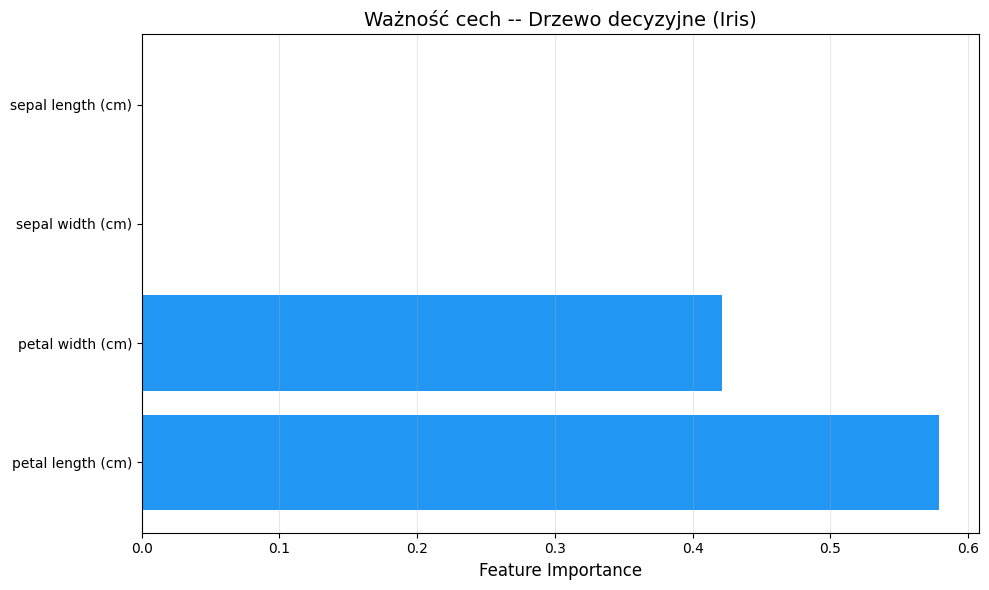

         petal length (cm): 0.5791
          petal width (cm): 0.4209
          sepal width (cm): 0.0000
         sepal length (cm): 0.0000


In [8]:
#zadanie 4
# Drzewo decyzyjne -- klasyfikacja irysów
from sklearn.tree import DecisionTreeClassifier, export_text
# Trening drzewa decyzyjnego
# max_depth ogranicza głębokość -- zapobiega overfitting
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_train, y_train) # BEZ standaryzacji -- drzewa NIE wymagają skalowania!
y_pred_tree = tree_clf.predict(X_test)
print("Drzewo decyzyjne (max_depth=3):")
print(classification_report(y_test, y_pred_tree, target_names=iris.target_names))
print()
# Wyświetlenie struktury drzewa jako tekst
print("Struktura drzewa:")
print(export_text(tree_clf, feature_names=iris.feature_names))
# Ważność cech w drzewie decyzyjnym
importances = tree_clf.feature_importances_
feature_names = iris.feature_names
# Sortowanie po ważności
indices = np.argsort(importances)[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(importances)), importances[indices], color='#2196F3')
ax.set_yticks(range(len(importances)))
ax.set_yticklabels([feature_names[i] for i in indices])
ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title('Ważność cech -- Drzewo decyzyjne (Iris)', fontsize=14)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
for i in indices:
  print(f" {feature_names[i]:>25s}: {importances[i]:.4f}")

In [11]:
# Zadanie 5 -- Random Forest baseline

import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

# 1. Wczytanie danych
data = load_breast_cancer()
X = data.data
y = data.target
# 2. Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# 3. Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    min_samples_split=5,
    n_jobs=-1
)
rf.fit(X_train, y_train)
# Predykcje klas i prawdopodobieństwa
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# 4. Logistic Regression ze standaryzacją
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

accuracy_lr = accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

# 5. Porównanie modeli
results = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "Accuracy": [accuracy_rf, accuracy_lr],
    "AUC": [auc_rf, auc_lr]
})

print(results.round(4))
#regresja logistyczna lepsza

                 Model  Accuracy     AUC
0        Random Forest    0.9474  0.9947
1  Logistic Regression    0.9825  0.9954


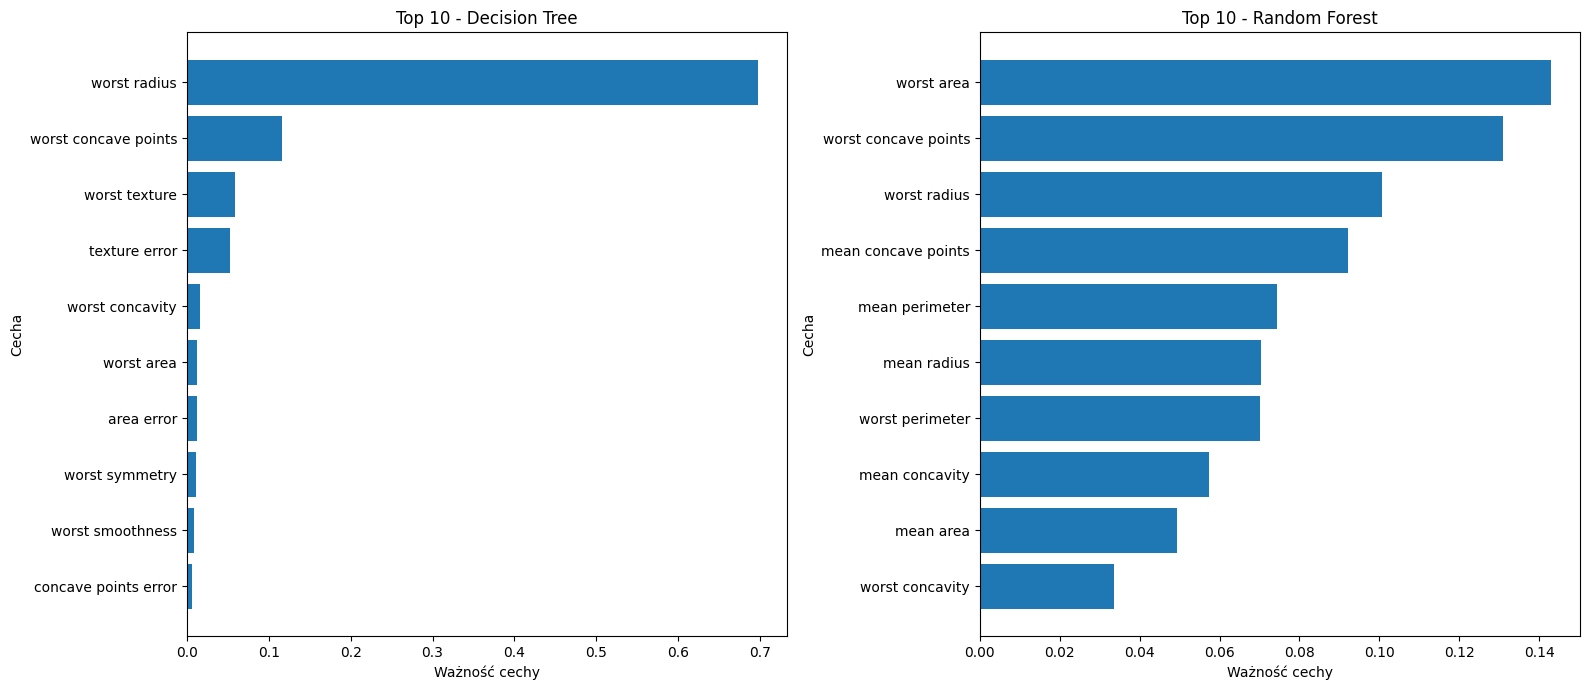

In [20]:
#zadanie 6

import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, export_text

# 1. Wczytanie danych
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

# 2. Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# 3. Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    min_samples_split=5,
    n_jobs=-1
)
rf.fit(X_train, y_train)
importances_rf = rf.feature_importances_

# 4. Decision Tree
dt = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
    )

dt.fit(X_train, y_train)
importances_dt = dt.feature_importances_
indices = np.argsort(importances_dt)[::-1]

# 5. Porównanie modeli

# Indeksy 10 najważniejszych cech dla każdego modelu
top10_dt = np.argsort(importances_dt)[-10:]
top10_rf = np.argsort(importances_rf)[-10:]

# Dwa wykresy obok siebie
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Decision Tree
axes[0].barh(
    feature_names[top10_dt],
    importances_dt[top10_dt]
)
axes[0].set_title("Top 10 - Decision Tree")
axes[0].set_xlabel("Ważność cechy")
axes[0].set_ylabel("Cecha")

# Random Forest
axes[1].barh(
    feature_names[top10_rf],
    importances_rf[top10_rf]
)
axes[1].set_title("Top 10 - Random Forest")
axes[1].set_xlabel("Ważność cechy")
axes[1].set_ylabel("Cecha")

plt.tight_layout()
plt.show()

"""Decision Tree opiera się przede wszystkim na cesze worst radius, której ważność wynosi około 0,7. Drugą najważniejszą cechą jest worst concave points, z wynikiem około 0,2. Oznacza to, że pojedyncze drzewo przypisuje większość łącznej ważności niewielkiej liczbie cech.

W przypadku Random Forest ważność cech jest rozłożona bardziej równomiernie, a żadna z nich nie przekracza wartości 0,2. Sugeruje to, że model wykorzystuje szerszy zestaw parametrów do podejmowania decyzji klasyfikacyjnych.

Wyniki wskazują, że Decision Tree w większym stopniu koncentruje się na wybranych cechach, natomiast Random Forest uwzględnia bardziej zróżnicowany zestaw cech. Może to wynikać z wykorzystania wielu drzew, które analizują różne kombinacje cech. Należy jednak pamiętać, że większa liczba istotnych cech nie oznacza automatycznie wyższej skuteczności modelu."""

In [22]:
# Zadanie 7 -- Gradient Boosting baseline

import time
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    roc_auc_score
)

# 1. Inicjalizacja modelu
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_split=5,
    random_state=42
)

# 2. Trening i pomiar czasu
start_time = time.perf_counter()

gb.fit(X_train_c, y_train_c)

training_time = time.perf_counter() - start_time

# 3. Predykcje
y_pred_gb = gb.predict(X_test_c)
y_proba_gb = gb.predict_proba(X_test_c)[:, 1]

# 4. Metryki
accuracy_gb = accuracy_score(y_test_c, y_pred_gb)
auc_gb = roc_auc_score(y_test_c, y_proba_gb)

# 5. Wyniki
print("Gradient Boosting")
print("-" * 40)
print(f"Accuracy:      {accuracy_gb:.4f}")
print(f"AUC:           {auc_gb:.4f}")
print(f"Czas treningu: {training_time:.4f} s")

print("\nRaport klasyfikacji:")
print(classification_report(
    y_test_c,
    y_pred_gb,
    target_names=cancer.target_names
))

Gradient Boosting
----------------------------------------
Accuracy:      0.9561
AUC:           0.9884
Czas treningu: 1.4614 s

Raport klasyfikacji:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



        Model  Mean Accuracy  Std Accuracy
          kNN         0.9733        0.0249
Decision Tree         0.9533        0.0340
Random Forest         0.9467        0.0267


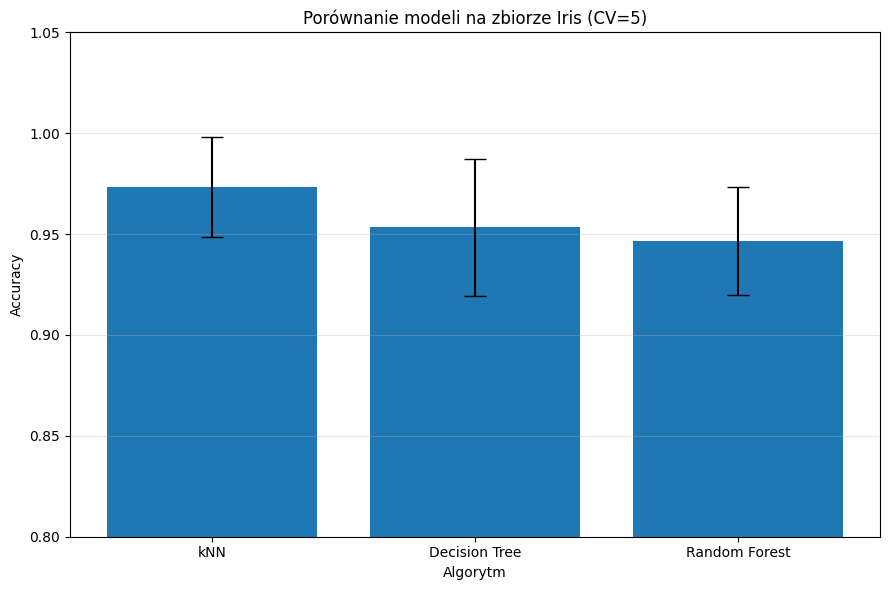


Najlepszy model: kNN
Średnia accuracy: 0.9733


In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Wczytanie danych
iris = load_iris()
X = iris.data
y = iris.target

# 2. Definicja modeli
models = {
    "kNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# 3. Walidacja krzyżowa (5 foldów)
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std Accuracy": scores.std()
    })

# 4. Tabela wyników
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

# 5. Wykres ze słupkami błędów
plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Model"],
    results_df["Mean Accuracy"],
    yerr=results_df["Std Accuracy"],
    capsize=8
)

plt.ylabel("Accuracy")
plt.xlabel("Algorytm")
plt.title("Porównanie modeli na zbiorze Iris (CV=5)")
plt.ylim(0.8, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Wskazanie najlepszego modelu
best_idx = results_df["Mean Accuracy"].idxmax()
best_model = results_df.loc[best_idx, "Model"]
best_accuracy = results_df.loc[best_idx, "Mean Accuracy"]

print(f"\nNajlepszy model: {best_model}")
print(f"Średnia accuracy: {best_accuracy:.4f}")


Porównanie modeli (CV=5):
            Model  Mean Accuracy  Std Accuracy    AUC  Czas (s)
    Random Forest         0.9112        0.0121 0.9153    2.8186
Gradient Boosting         0.8993        0.0093 0.9015    3.1522
          XGBoost         0.8949        0.0144 0.9024    1.3713


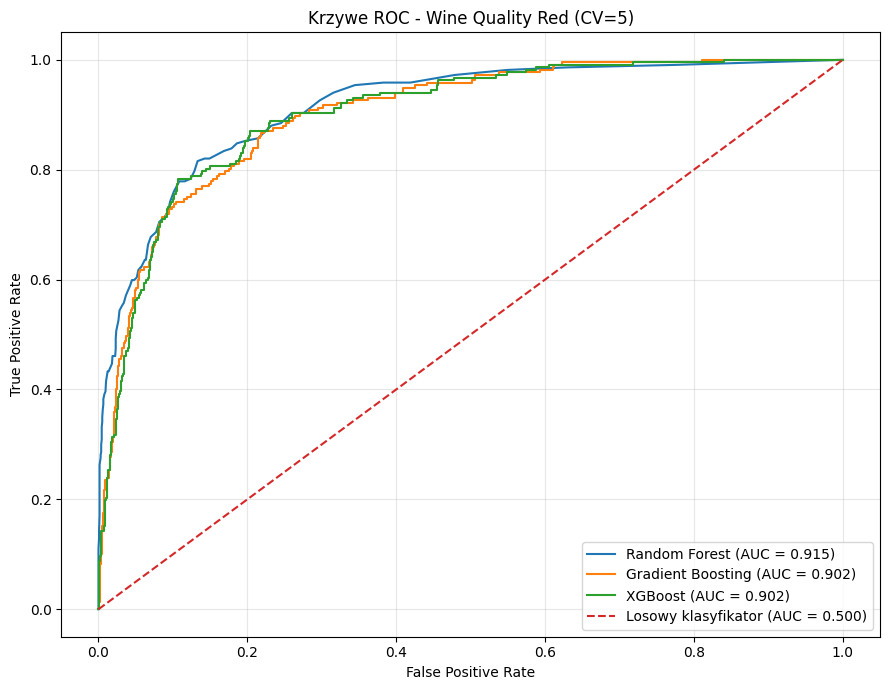


Najlepszy model według AUC: Random Forest
AUC: 0.9153


In [29]:
# Zadanie 11 - Random Forest vs Gradient Boosting vs XGBoost

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    roc_curve
)

# 1. Wczytanie danych
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")

X = df.drop(columns="quality")
y = (df["quality"] >= 7).astype(int)

# 2. Definicja modeli
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        min_samples_split=5,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        eval_metric="logloss"
    )
}

# 3. Walidacja krzyżowa
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
oof_probabilities = {}

for name, model in models.items():

    # Tablica na prawdopodobieństwa out-of-fold
    oof_probs = np.zeros(len(y))
    fold_accuracies = []

    start_time = time.perf_counter()

    for train_idx, test_idx in cv.split(X, y):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        clf = clone(model)
        clf.fit(X_train, y_train)

        # Predykcje
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)[:, 1]

        oof_probs[test_idx] = y_prob
        fold_accuracies.append(
            accuracy_score(y_test, y_pred)
        )

    training_time = time.perf_counter() - start_time

    # AUC z połączonych predykcji out-of-fold
    auc = roc_auc_score(y, oof_probs)

    results.append({
        "Model": name,
        "Mean Accuracy": np.mean(fold_accuracies),
        "Std Accuracy": np.std(fold_accuracies),
        "AUC": auc,
        "Czas (s)": training_time
    })

    oof_probabilities[name] = oof_probs

# 4. Tabela wyników
results_df = pd.DataFrame(results)

print("Porównanie modeli (CV=5):")
print(results_df.round(4).to_string(index=False))

# 5. Krzywe ROC
plt.figure(figsize=(9, 7))

for name, probs in oof_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y, probs)
    auc = roc_auc_score(y, probs)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Linia losowego klasyfikatora
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Losowy klasyfikator (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Krzywe ROC - Wine Quality Red (CV=5)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Najlepszy model według AUC
best_idx = results_df["AUC"].idxmax()

print("\nNajlepszy model według AUC:",
      results_df.loc[best_idx, "Model"])
print("AUC:",
      round(results_df.loc[best_idx, "AUC"], 4))


In [34]:
#zaddanie 12
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Wczytanie danych
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# 2. Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Domyślny Random Forest
rf_default = RandomForestClassifier(
    random_state=42
)

rf_default.fit(X_train, y_train)

y_pred_default = rf_default.predict(X_test)
accuracy_default = accuracy_score(y_test, y_pred_default)

# 4. Przestrzeń parametrów
param_dist = {
    "n_estimators": list(range(50, 301)),
    "max_depth": list(range(3, 21)),
    "min_samples_split": list(range(2, 21)),
    "min_samples_leaf": list(range(1, 11))
}

# 5. RandomizedSearchCV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf = RandomForestClassifier(
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=30,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

# 6. Najlepsze parametry
print("Najlepsze parametry:")
print(random_search.best_params_)

print("\nNajlepsza średnia accuracy z CV:")
print(round(random_search.best_score_, 4))

# 7. Ocena zoptymalizowanego modelu na zbiorze testowym
rf_optimized = random_search.best_estimator_

y_pred_optimized = rf_optimized.predict(X_test)
accuracy_optimized = accuracy_score(y_test, y_pred_optimized)

# 8. Porównanie modeli
results = pd.DataFrame({
    "Model": ["Random Forest domyślny", "Random Forest zoptymalizowany"],
    "Accuracy": [accuracy_default, accuracy_optimized]
})

print("\nPorównanie accuracy na zbiorze testowym:")
print(results.round(4).to_string(index=False))

# 9. Różnica wyników
difference = accuracy_optimized - accuracy_default

print(f"\nZmiana accuracy: {difference:+.4f}")
print(f"Zmiana w punktach procentowych: {difference * 100:+.2f} p.p.")
#Jest różnica pomiędzy Accuracy na zbiorze testowym, a na zbioże treningowym. Mamy mały overfitting

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Najlepsze parametry:
{'n_estimators': 63, 'min_samples_split': 12, 'min_samples_leaf': 4, 'max_depth': 18}

Najlepsza średnia accuracy z CV:
0.9582

Porównanie accuracy na zbiorze testowym:
                        Model  Accuracy
       Random Forest domyślny    0.9561
Random Forest zoptymalizowany    0.9474

Zmiana accuracy: -0.0088
Zmiana w punktach procentowych: -0.88 p.p.


Najlepsza kombinacja dla każdej metryki:
  Metryka  k  Accuracy_mean  Accuracy_std
manhattan  9         0.9684        0.0163
euclidean  9         0.9666        0.0161
minkowski 12         0.9649        0.0124
chebyshev  6         0.9455        0.0171


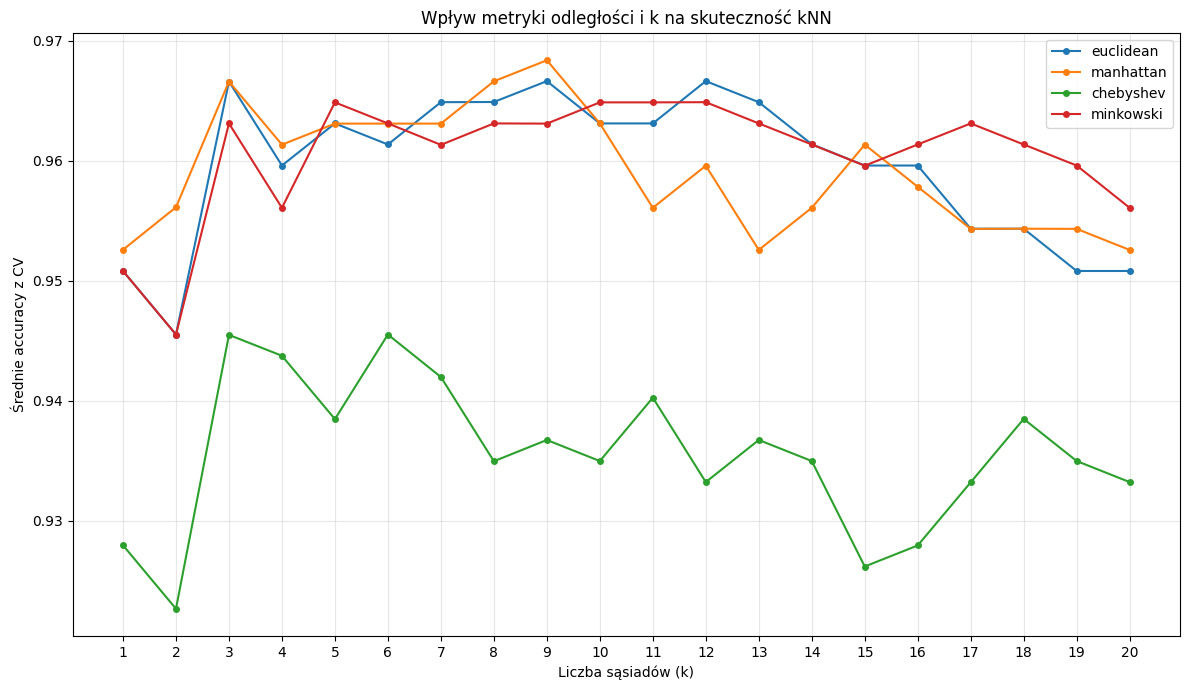


Accuracy dla poszczególnych wartości k:
Metryka  chebyshev  euclidean  manhattan  minkowski
k                                                  
1           0.9279     0.9508     0.9526     0.9508
2           0.9227     0.9455     0.9561     0.9455
3           0.9455     0.9666     0.9666     0.9631
4           0.9437     0.9596     0.9613     0.9561
5           0.9385     0.9631     0.9631     0.9649
6           0.9455     0.9613     0.9631     0.9631
7           0.9420     0.9649     0.9631     0.9613
8           0.9349     0.9649     0.9666     0.9631
9           0.9367     0.9666     0.9684     0.9631
10          0.9350     0.9631     0.9631     0.9649
11          0.9402     0.9631     0.9561     0.9649
12          0.9332     0.9666     0.9596     0.9649
13          0.9367     0.9649     0.9526     0.9631
14          0.9350     0.9614     0.9561     0.9613
15          0.9262     0.9596     0.9613     0.9596
16          0.9279     0.9596     0.9578     0.9613
17          0.9332     

In [35]:
#Zadanie 14 -- kNN z różnymi metrykami odległości

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Wczytanie danych
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Konfiguracja walidacji krzyżowej
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Badane metryki
metrics = {
    "euclidean": {"metric": "euclidean"},
    "manhattan": {"metric": "manhattan"},
    "chebyshev": {"metric": "chebyshev"},
    "minkowski": {"metric": "minkowski", "p": 3}
}

k_values = range(1, 21)
results = []

# 4. Testowanie każdej metryki i wartości k
for metric_name, params in metrics.items():
    for k in k_values:

        model = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(
                n_neighbors=k,
                **params
            )
        )

        scores = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )

        results.append({
            "Metryka": metric_name,
            "k": k,
            "Accuracy_mean": scores.mean(),
            "Accuracy_std": scores.std()
        })

# 5. Wyniki w DataFrame
results_df = pd.DataFrame(results)

# 6. Najlepsze k dla każdej metryki
best_results = (
    results_df
    .loc[results_df.groupby("Metryka")["Accuracy_mean"].idxmax()]
    .sort_values("Accuracy_mean", ascending=False)
)

print("Najlepsza kombinacja dla każdej metryki:")
print(
    best_results[
        ["Metryka", "k", "Accuracy_mean", "Accuracy_std"]
    ].round(4).to_string(index=False)
)

# 7. Wykres liniowy
plt.figure(figsize=(12, 7))

for metric_name in metrics:
    subset = results_df[results_df["Metryka"] == metric_name]

    plt.plot(
        subset["k"],
        subset["Accuracy_mean"],
        marker="o",
        markersize=4,
        label=metric_name
    )

plt.xlabel("Liczba sąsiadów (k)")
plt.ylabel("Średnie accuracy z CV")
plt.title("Wpływ metryki odległości i k na skuteczność kNN")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 8. Tabela porównująca accuracy dla wszystkich wartości k
pivot_table = results_df.pivot(
    index="k",
    columns="Metryka",
    values="Accuracy_mean"
)

print("\nAccuracy dla poszczególnych wartości k:")
print(pivot_table.round(4))
